In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
# while using virtual env
#df=pd.read_csv("news_article_classification_data.csv")

#using colab kernel
df=pd.read_csv("drive/MyDrive/Dataset/news_article_classification_data.csv")
df.head()
# df1=pd.read_csv("news_multilabel_merged_cleaned.csv")
# df.head()

,title,text,labels,url,section,revised_labels,label_cat_list
0,Megan Davies obituary,"My partner, Megan Davies, who has died aged 67...","['Politics', 'Technology']",https://www.theguardian.com/politics/2025/dec/...,politics,"['Politics', 'Technology']","[1, 1, 0, 0, 0, 0, 0, 0]"
1,Nigel Farage told to apologise by 26 of his sc...,Nigel Farage has been told to apologise for hi...,"['Politics', 'Technology']",https://www.theguardian.com/politics/2025/dec/...,politics,"['Politics', 'Technology']","[1, 1, 0, 0, 0, 0, 0, 0]"
2,Dulwich college head responds to claims of tee...,Dulwich college’s headteacher has responded to...,"['Politics', 'Technology']",https://www.theguardian.com/politics/2025/dec/...,politics,"['Politics', 'Technology']","[1, 1, 0, 0, 0, 0, 0, 0]"
3,Badenoch criticises Farage over refusal to apo...,Kemi Badenoch has questioned why Nigel Farage ...,"['Politics', 'Technology']",https://www.theguardian.com/politics/2025/dec/...,politics,"['Politics', 'Technology']","[1, 1, 0, 0, 0, 0, 0, 0]"
4,Nigel Farage is wrong – victims don’t forget b...,Regarding Nigel Farage’s difficulty believing ...,"['Politics', 'Technology']",https://www.theguardian.com/politics/2025/dec/...,politics,"['Politics', 'Technology']","[1, 1, 0, 0, 0, 0, 0, 0]"


In [ ]:
df['labels'].unique()

array(["['Politics', 'Technology']", "['Politics', 'Business']",
       "['Economy', 'Politics']", "['Sports', 'Politics']",
       "['International_Affairs', 'Politics']",
       "['Politics', 'Education']",
       "['International_Affairs', 'Technology']",
       "['International_Affairs', 'Business']",
       "['International_Affairs', 'Economy']",
       "['International_Affairs', 'Sports']",
       "['International_Affairs', 'Health']",
       "['International_Affairs', 'Energy']", "['Economy', 'Business']",
       "['Economy', 'Business', 'Politics']",
       "['Technology', 'Economy', 'Business']",
       "['Health', 'Economy', 'Business']",
       "['Crime', 'Economy', 'Business']", "['Business', 'Technology']",
       "['Economy', 'Technology']", "['Education', 'Technology']",
       "['Health', 'Technology']", "['Science', 'Technology']",
       "['Energy', 'Technology']", "['Science', 'Business']",
       "['Science', 'Politics']", "['Science', 'Economy']",
       "['Science

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47587 entries, 0 to 47586
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   title           47587 non-null  object
 1   text            47587 non-null  object
 2   labels          47587 non-null  object
 3   url             47587 non-null  object
 4   section         47587 non-null  object
 5   revised_labels  47587 non-null  object
 6   label_cat_list  47587 non-null  object
dtypes: object(7)
memory usage: 2.5+ MB


In [ ]:
df.describe()

,title,text,labels,url,section,revised_labels,label_cat_list
count,47587,47587,47587,47587,47587,47587,47587
unique,47568,47587,49,47587,7,38,36
top,UK inflation: which goods and services have ch...,"Wild plants, animals, fungi and algae support ...","['International_Affairs', 'Politics']",https://www.theguardian.com/environment/2022/j...,business,"['International_Affairs', 'Politics']","[1, 0, 0, 0, 1, 0, 0, 0]"
freq,9,1,7697,1,9985,7697,7697


In [ ]:
print(df.duplicated().sum())
print(df['text'].duplicated().sum())
print(df['title'].duplicated().sum())

0
0
19


## 1. Data Preprocessing & Setup
We will parse the labels and create columns for our three scenarios (Title, Text, Title+Text).


In [ ]:
import ast
import torch
import re
from torch.utils.data import Dataset, DataLoader
from transformers import DistilBertTokenizer, DistilBertModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, hamming_loss
import numpy as np

In [ ]:
# Convert string representation of list to actual Python list
df['label_cat_list'] = df['label_cat_list'].apply(ast.literal_eval)

In [ ]:
df['label_cat_list'].dtype

dtype('O')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47587 entries, 0 to 47586
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   title           47587 non-null  object
 1   text            47587 non-null  object
 2   labels          47587 non-null  object
 3   url             47587 non-null  object
 4   section         47587 non-null  object
 5   revised_labels  47587 non-null  object
 6   label_cat_list  47587 non-null  object
dtypes: object(7)
memory usage: 2.5+ MB


In [ ]:
df['label_cat_list'].iloc[0]

[1, 1, 0, 0, 0, 0, 0, 0]

In [ ]:
def clean_text(text):

    # Convert to lowercase
    text = text.lower()
    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    # Remove URLs
    text = re.sub(r'http\S+|www\.\S+', '', text)
    # Remove special characters (keeping basic punctuation for BERT context)
    text = re.sub(r'[^a-zA-Z0-9\s.,!?;:-]', '', text)
    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text


In [ ]:
# Apply cleaning to title and text
df['title_cleaned'] = df['title'].apply(clean_text)


Cleaning 'title' column...


In [ ]:
df['title_cleaned']

,title_cleaned
0,megan davies obituary
1,nigel farage told to apologise by 26 of his sc...
2,dulwich college head responds to claims of tee...
3,badenoch criticises farage over refusal to apo...
4,nigel farage is wrong victims dont forget bull...
...,...
47582,fears environment bills could be sidelined ami...
47583,country diary: we should open our eyes to the ...
47584,poacher who took 60k of salmon and trout from ...
47585,victims of brazils worst environmental disaste...


In [ ]:
df['text_cleaned'] = df['text'].apply(clean_text)


Cleaning 'text' column...


In [ ]:
# Create the Title + Text combination
df['combined'] = df['title_cleaned'] + " - " + df['text_cleaned']

In [ ]:
# Number of labels
num_labels = len(df['label_cat_list'].iloc[0])
print(f"Number of categories: {num_labels}")

Number of categories: 8


In [ ]:
df['label_cat_list'].dtype

dtype('O')

## 2. Tokenization and Dataset 

In [ ]:
class NewsDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, item):
        text = str(self.texts[item])
        label = self.labels[item]

        encoding = self.tokenizer(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            return_token_type_ids=False,
            padding='max_length',
            truncation=True,
            return_attention_mask=True,
            return_tensors='pt',
        )

        return {
            'text': text,
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.float)
        }

tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

## 3. DistilBERT Multi-Label Model (sample)
We add a linear layer with Sigmoid activation on top of the DistilBERT encoder.


In [ ]:
import torch.nn as nn

class DistilBertMultiLabelClassifier(nn.Module):
    def __init__(self, n_classes):
        super(DistilBertMultiLabelClassifier, self).__init__()
        self.distilbert = DistilBertModel.from_pretrained('distilbert-base-uncased')
        self.dropout = nn.Dropout(0.3)
        self.classifier =nn.Sequential(
            nn.Linear(self.distilbert.config.hidden_size, 512),
            nn.ReLU(),

            nn.Dropout(0.2),
            nn.Linear(512,n_classes)
        )

    def forward(self, input_ids, attention_mask):
        output = self.distilbert(input_ids=input_ids, attention_mask=attention_mask)
        pooled_output = output.last_hidden_state[:, 0] 
        pooled_output = self.dropout(pooled_output)
        logits = self.classifier(pooled_output)
        return logits


## 4. Data Preparation

In [ ]:
sample_df = df.sample(n=5000, random_state=42)
text_column = 'combined'

X_train, X_test, y_train, y_test = train_test_split(
    sample_df[text_column],
    sample_df['label_cat_list'],
    test_size=0.2,
    random_state=42
)
print(f"Data Split Complete. Training set size: {len(X_train)}")

Data Split Complete. Training set size: 4000


## 5. Setup DataLoaders

In [ ]:
batch_size = 32

train_dataset = NewsDataset(X_train.to_numpy(), y_train.to_numpy(), tokenizer)
test_dataset = NewsDataset(X_test.to_numpy(), y_test.to_numpy(), tokenizer)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
print("DataLoaders are ready.")

DataLoaders are ready.


## 6. Model Initialization

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [ ]:
model = DistilBertMultiLabelClassifier(num_labels).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## 7. Training Function

In [ ]:
from sklearn.metrics import accuracy_score

def train_model(model, train_loader, criterion, optimizer, device, epochs=3, val_loader=None):
    print("Starting Training...")
    history = {'train_loss': [], 'train_acc': [], 'val_macro_f1': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        all_preds = []
        all_labels = []
        for batch in train_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            optimizer.zero_grad()
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()
            total_loss += loss.item()

            probs = torch.sigmoid(logits)
            preds = (probs > 0.5).int()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

        train_acc = accuracy_score(all_labels, all_preds)
        avg_train_loss = total_loss / len(train_loader)

        history['train_loss'].append(avg_train_loss)
        history['train_acc'].append(train_acc)

        print(f"Epoch {epoch+1}/{epochs} - Avg Train Loss: {avg_train_loss:.4f} - Train Acc: {train_acc:.4f}")

        if val_loader is not None:
            # Evaluate using existing eval_model function
            val_results = eval_model(model, val_loader, device)
            history['val_macro_f1'].append(val_results.get('macro_f1', 0))
            history['val_acc'].append(val_results.get('accuracy', 0))

    return model, history


## 8. Evaluation Function

In [ ]:
def eval_model(model, test_loader, device):
    from sklearn.metrics import f1_score, hamming_loss, accuracy_score
    print("\nEvaluating Model...")
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in test_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            logits = model(input_ids, attention_mask)
            probs = torch.sigmoid(logits)
            preds = (probs > 0.5).int()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    micro_f1 = f1_score(all_labels, all_preds, average='micro')
    macro_f1 = f1_score(all_labels, all_preds, average='macro')
    h_loss = hamming_loss(all_labels, all_preds)
    acc = accuracy_score(all_labels, all_preds)

    print(f"Accuracy:       {acc:.4f}")
    print(f"Micro F1-score: {micro_f1:.4f}")
    print(f"Macro F1-score: {macro_f1:.4f}")
    print(f"Hamming Loss:   {h_loss:.4f}")

    return {'accuracy': acc, 'micro_f1': micro_f1, 'macro_f1': macro_f1, 'hamming_loss': h_loss}


## 9. Execute Training and Evaluation

In [ ]:
# Train the model with validation and save history
model, baseline_history = train_model(model, train_loader, criterion, optimizer, device, epochs=5, val_loader=test_loader)

# Final Evaluation
results = eval_model(model, test_loader, device)


Starting Training...
Epoch 1/5 - Avg Train Loss: 0.4607 - Train Acc: 0.1578

Evaluating Model...
Accuracy:       0.4720
Micro F1-score: 0.7751
Macro F1-score: 0.7572
Hamming Loss:   0.1120
Epoch 2/5 - Avg Train Loss: 0.2830 - Train Acc: 0.5373

Evaluating Model...
Accuracy:       0.5720
Micro F1-score: 0.8116
Macro F1-score: 0.8251
Hamming Loss:   0.0983
Epoch 3/5 - Avg Train Loss: 0.2179 - Train Acc: 0.6310

Evaluating Model...
Accuracy:       0.5790
Micro F1-score: 0.8148
Macro F1-score: 0.8287
Hamming Loss:   0.0965
Epoch 4/5 - Avg Train Loss: 0.1768 - Train Acc: 0.6937

Evaluating Model...
Accuracy:       0.6040
Micro F1-score: 0.8231
Macro F1-score: 0.8399
Hamming Loss:   0.0919
Epoch 5/5 - Avg Train Loss: 0.1430 - Train Acc: 0.7502

Evaluating Model...
Accuracy:       0.6130
Micro F1-score: 0.8268
Macro F1-score: 0.8428
Hamming Loss:   0.0906

Evaluating Model...
Accuracy:       0.6130
Micro F1-score: 0.8268
Macro F1-score: 0.8428
Hamming Loss:   0.0906


## 10. Save the Trained Model


In [ ]:
import os

# 1. Save the Tokenizer
tokenizer.save_pretrained('saved_distilbert_tokenizer')

# 2. Save the Custom PyTorch Model Weights
torch.save(model.state_dict(), 'distilbert_multilabel_weights.pth')

print("Model and tokenizer successfully saved to disk!")

Model and tokenizer successfully saved to disk!


### Save to drive

In [ ]:
# 1. Save the Tokenizer
tokenizer.save_pretrained('/content/MyDrive/Models/saved_distilbert_tokenizer')

# 2. Save the Custom PyTorch Model Weights
torch.save(model.state_dict(), '/content/MyDrive/Models/distilbert_multilabel_weights.pth')

print("Model and tokenizer successfully saved to drive!")

Model and tokenizer successfully saved to drive!


In [ ]:
from google.colab import files

## downolad the file if needed

In [ ]:
files.download('/content/distilbert_multilabel_weights.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
from google.colab import files

# 1. Zip the tokenizer folder
# This creates 'saved_distilbert_tokenizer.zip'
shutil.make_archive('saved_distilbert_tokenizer', 'zip', 'saved_distilbert_tokenizer')

# 2. Download the zip file to your local machine
files.download('saved_distilbert_tokenizer.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Convert the dictionary to a DataFrame first, then call to_json()
pd.DataFrame(baseline_history).to_json()

'{"train_loss":{"0":0.460731636,"1":0.2829735202,"2":0.2179465017,"3":0.1768072393,"4":0.1430429317},"train_acc":{"0":0.15775,"1":0.53725,"2":0.631,"3":0.69375,"4":0.75025},"val_macro_f1":{"0":0.7572056099,"1":0.8250799159,"2":0.8287097719,"3":0.8398946447,"4":0.8428095246},"val_acc":{"0":0.472,"1":0.572,"2":0.579,"3":0.604,"4":0.613}}'

In [ ]:
# Save the history to a JSON file
baseline_df = pd.DataFrame(baseline_history)
baseline_df.to_json('baseline_metrics.json', indent=4)
print("Baseline metrics saved to 'baseline_metrics.json'")

Baseline metrics saved to 'baseline_metrics.json'


## 11. Load the Model & Make Predictions


In [ ]:

loaded_tokenizer = DistilBertTokenizer.from_pretrained('/content/saved_distilbert_tokenizer')

#re-initialize the model
loaded_model = DistilBertMultiLabelClassifier(num_labels)

# Load the trained weights into the architecture
loaded_model.load_state_dict(torch.load('/content/distilbert_multilabel_weights.pth', map_location=device))
loaded_model.to(device)
loaded_model.eval() # Set to evaluation mode

Loading saved tokenizer and model...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBertMultiLabelClassifier(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)
     

In [ ]:
category_names = [
        'Politics', 'Technology', 'Business', 'Economy',
        'International_Affairs', 'Education', 'Health', 'Science/Other'
    ]

In [ ]:

def predict_news_category(raw_text, model, tokenizer, device, threshold=0.4):
    
    category_names = [
        'Politics', 'Technology', 'Business', 'Economy',
        'International_Affairs', 'Education', 'Health', 'Science/Other'
    ]

    cleaned_text = clean_text(raw_text)

    encoding = tokenizer(
        cleaned_text,
        add_special_tokens=True,
        max_length=256,
        padding='max_length',
        truncation=True,
        return_attention_mask=True,
        return_tensors='pt'
    )

    input_ids = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)

    with torch.no_grad():
        logits = model(input_ids, attention_mask)
        probs = torch.sigmoid(logits)
        predictions_array = (probs > threshold).int().cpu().numpy()[0]
        raw_confidence = probs.cpu().numpy()[0]

    predicted_labels = []
    for i, is_predicted in enumerate(predictions_array):
        if is_predicted == 1:
            cat_name = category_names[i] if i < len(category_names) else f"Category_{i}"
            predicted_labels.append(cat_name)

    return predicted_labels, raw_confidence

In [ ]:

custom_article = "US clearing Strait of Hormuz as a favour to the world, says Trump; targets other nations for lack of courage US President Donald Trump today announced that the United States has initiated steps to “clear out” the Strait of Hormuz, calling the move a ‘favour to the world’ to ensure uninterrupted global energy supplies. In a statement on Truth Social, Trump said the effort is intended to benefit countries across the world, naming major economies such as China, Japan, South Korea, France and Germany. He positioned the initiative as part of a broader attempt to stabilise maritime trade routes amid rising tensions in the region."
labels, scores = predict_news_category(custom_article, loaded_model, loaded_tokenizer, device)

print(f"\nArticle: '{custom_article}'")
print(f"Predicted Categories: {labels}")
print(f"Raw Confidence Output: {np.round(scores, 3)}")


Article: 'US clearing Strait of Hormuz as a favour to the world, says Trump; targets other nations for lack of courage US President Donald Trump today announced that the United States has initiated steps to “clear out” the Strait of Hormuz, calling the move a ‘favour to the world’ to ensure uninterrupted global energy supplies. In a statement on Truth Social, Trump said the effort is intended to benefit countries across the world, naming major economies such as China, Japan, South Korea, France and Germany. He positioned the initiative as part of a broader attempt to stabilise maritime trade routes amid rising tensions in the region.'
Predicted Categories: ['Politics', 'International_Affairs']
Raw Confidence Output: [0.936 0.046 0.029 0.03  0.985 0.008 0.008 0.014]


## Hyperparameter Tuning with Optuna


In [ ]:
! pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 11.6 MB/s eta 0:00:00


In [ ]:
import optuna
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.utils.data import DataLoader
import torch
from sklearn.metrics import f1_score, accuracy_score, hamming_loss
from sklearn.model_selection import train_test_split
import pandas as pd

In [ ]:
len(df)*(15/100)

7138.05

In [ ]:
sample_df = df.sample(frac=0.15, random_state=42)
text_column = 'combined'

In [ ]:
X_tune_train, X_tune_val, y_tune_train, y_tune_val = train_test_split(
    sample_df[text_column],
    sample_df['label_cat_list'],
    test_size=0.2,
    random_state=42
)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [ ]:
num_labels = len(df['label_cat_list'].iloc[0])
print(f"Number of categories: {num_labels}")

Number of categories: 8


In [ ]:
import torch.nn as nn
from sklearn.metrics import f1_score, accuracy_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification

def objective(trial):

    model_name = trial.suggest_categorical("model_name", ["distilbert-base-uncased", "roberta-base", "microsoft/deberta-v3-base"])

    if model_name == "distilbert-base-uncased":
      lr = trial.suggest_float("distilbert_lr", 5e-6, 5e-5, log=True)
      batch_size = trial.suggest_categorical("distilbert_batch_size", [16, 32, 64])
      weight_decay = trial.suggest_float("distilbert_weight_decay", 1e-3, 5e-2, log=True)
      warmup_ratio = trial.suggest_float("distilbert_warmup_ratio", 0.0, 0.1)
      max_length = trial.suggest_categorical("distilbert_max_length", [128, 256])
      epochs = trial.suggest_int("distilbert_epochs", 2, 5)
    elif model_name == "roberta-base":
      lr = trial.suggest_float("roberta_lr", 1e-6, 3e-5, log=True)
      batch_size = trial.suggest_categorical("roberta_batch_size", [16, 32])
      weight_decay = trial.suggest_float("roberta_weight_decay", 1e-4, 1e-2, log=True)
      warmup_ratio = trial.suggest_float("roberta_warmup_ratio", 0.05, 0.2)
      max_length = trial.suggest_categorical("roberta_max_length", [128, 256])
      epochs = trial.suggest_int("roberta_epochs", 3, 6)
    elif model_name == "microsoft/deberta-v3-base":
      lr = trial.suggest_float("deberta_lr", 5e-7, 2e-5, log=True)
      batch_size = trial.suggest_categorical("deberta_batch_size", [4])
      weight_decay = trial.suggest_float("deberta_weight_decay", 1e-5, 1e-3, log=True)
      warmup_ratio = trial.suggest_float("deberta_warmup_ratio", 0.01, 0.1)
      max_length = trial.suggest_categorical("deberta_max_length", [64])
      epochs = trial.suggest_int("deberta_epochs", 3, 5)

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=num_labels,
        problem_type="multi_label_classification"
    ).to(device)

    tune_train_dataset = NewsDataset(X_tune_train.to_numpy(), y_tune_train.to_numpy(), tokenizer, max_len=max_length)
    tune_val_dataset = NewsDataset(X_tune_val.to_numpy(), y_tune_val.to_numpy(), tokenizer, max_len=max_length)

    tune_train_loader = DataLoader(tune_train_dataset, batch_size=batch_size, shuffle=True, pin_memory=True)
    tune_val_loader = DataLoader(tune_val_dataset, batch_size=batch_size, shuffle=False, pin_memory=True)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    total_steps = len(tune_train_loader) * epochs
    num_warmup_steps = int(total_steps * warmup_ratio)
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=num_warmup_steps, num_training_steps=total_steps)

    for epoch in range(epochs):
        model.train()
        for batch in tune_train_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)
            optimizer.zero_grad()
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            loss.backward()
            optimizer.step()
            scheduler.step()

    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in tune_val_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            probs = torch.sigmoid(outputs.logits)
            preds = (probs > 0.5).int()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    macro_f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    acc = accuracy_score(all_labels, all_preds)
    trial.set_user_attr("accuracy", acc)

    print(f"Trial {trial.number} finished | Model Used: {model_name} | Macro F1: {macro_f1:.4f} | Accuracy: {acc:.4f}")

    return macro_f1

In [ ]:
study = optuna.create_study(
    study_name="transformer_tuning",
    storage="sqlite:///optuna_study.db",
    load_if_exists=True,
    direction="maximize"
)

[I 2026-04-14 18:03:52,076] Using an existing study with name 'transformer_tuning' instead of creating a new one.


In [ ]:
import sys
import os

original_stderr = sys.stderr

with open(os.devnull, 'w') as fnull:
    sys.stderr = fnull
    try:
        study.optimize(objective, n_trials=15)
    finally:
        sys.stderr = original_stderr 

print("\n" + "="*50)
print("             OPTIMIZATION SUMMARY            ")
print("="*50)
print("Best Macro F1 Score:", study.best_trial.value)

accuracy = study.best_trial.user_attrs.get('accuracy', 'N/A')
print(f"Best Trial Metrics:")
print(f"  Accuracy:      {accuracy if isinstance(accuracy, str) else f'{accuracy:.4f}'}")

print("\nBest Trial Hyperparameters:")
for key, value in study.best_trial.params.items():
    print(f"  {key}: {value}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[I 2026-04-14 13:08:13,894] Trial 0 finished with value: 0.852801972466278 and parameters: {'model_name': 'distilbert-base-uncased', 'distilbert_lr': 1.710291116330444e-05, 'distilbert_batch_size': 16, 'distilbert_weight_decay': 0.007

Trial 0 finished | Model Used: distilbert-base-uncased | Macro F1: 0.8528 | Accuracy: 0.6254


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

... (26 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[I 2026-04-14 14:35:29,999] Trial 10 finished with value: 0.8595310835544688 and parameters: {'model_name': 'rob

Trial 10 finished | Model Used: roberta-base | Macro F1: 0.8595 | Accuracy: 0.6317


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

In [ ]:
# Fetch history as dataframe
df_trials = study.trials_dataframe()
df_trials

,number,value,datetime_start,datetime_complete,duration,params_batch_size,params_epochs,params_lr,params_max_length,params_model_name,params_use_extra_layer,params_warmup_ratio,params_weight_decay,user_attrs_accuracy,state
0,0,NaN,2026-04-14 03:19:52.595153,2026-04-14 03:20:07.406014,0 days 00:00:14.810861,16,5,0.000007,128,microsoft/deberta-v3-base,True,0.023245,0.018554,NaN,FAIL
1,1,NaN,2026-04-14 03:21:05.696322,2026-04-14 03:21:12.753756,0 days 00:00:07.057434,16,5,0.000037,128,microsoft/deberta-v3-base,True,0.168478,0.000393,NaN,FAIL
2,2,NaN,2026-04-14 03:22:22.804928,2026-04-14 03:22:38.898085,0 days 00:00:16.093157,32,5,0.000059,256,roberta-base,True,0.149408,0.008669,NaN,FAIL
3,3,0.000000,2026-04-14 03:24:32.959376,2026-04-14 03:28:10.920839,0 days 00:03:37.961463,16,2,0.000068,256,microsoft/deberta-v3-base,NaN,0.013320,0.001393,0.000000,COMPLETE
4,4,0.829923,2026-04-14 03:28:10.951804,2026-04-14 03:35:08.569116,0 days 00:06:57.617312,16,3,0.000005,128,roberta-base,NaN,0.136395,0.007178,0.560924,COMPLETE
5,5,0.821796,2026-04-14 03:35:08.589949,2026-04-14 03:44:14.321534,0 days 00:09:05.731585,32,2,0.000009,256,roberta-base,NaN,0.051895,0.000164,0.538515,COMPLETE
6,6,0.856180,2026-04-14 03:44:14.340764,2026-04-14 04:06:41.442214,0 days 00:22:27.101450,16,5,0.000009,256,roberta-base,NaN,0.088558,0.000104,0.646359,COMPLETE
7,7,0.851498,2026-04-14 04:06:41.465485,2026-04-14 04:11:23.676435,0 days 00:04:42.210950,32,2,0.000065,256,distilbert-base-uncased,NaN,0.024339,0.001001,0.614146,COMPLETE
8,8,0.743291,2026-04-14 04:11:23.693122,2026-04-14 04:13:39.853945,0 days 00:02:16.160823,32,2,0.000011,128,distilbert-base-uncased,NaN,0.085306,0.009445,0.437675,COMPLETE
9,9,0.000000,2026-04-14 04:13:39.876812,2026-04-14 04:20:33.025841,0 days 00:06:53.149029,16,4,0.000006,256,microsoft/deberta-v3-base,NaN,0.131861,0.057702,0.000000,COMPLETE


In [ ]:
# Save to a physical file for direct use
df_trials.to_csv('optuna_hyperparameters_history.csv', index=False)

In [ ]:
print("\n[+] Saved complete hyperparameter history to 'optuna_hyperparameters_history.csv'")
cols_to_show = ['number', 'state', 'value', 'params_model_name', 'params_lr', 'user_attrs_accuracy', 'user_attrs_micro_f1']
available_cols = [c for c in cols_to_show if c in df_trials.columns]
if len(available_cols) > 0:
    print(df_trials[available_cols].to_string(index=False))



[+] Saved complete hyperparameter history to 'optuna_hyperparameters_history.csv'
 number    state    value         params_model_name  params_lr  user_attrs_accuracy
      0     FAIL      NaN microsoft/deberta-v3-base   0.000007                  NaN
      1     FAIL      NaN microsoft/deberta-v3-base   0.000037                  NaN
      2     FAIL      NaN              roberta-base   0.000059                  NaN
      3 COMPLETE 0.000000 microsoft/deberta-v3-base   0.000068             0.000000
      4 COMPLETE 0.829923              roberta-base   0.000005             0.560924
      5 COMPLETE 0.821796              roberta-base   0.000009             0.538515
      6 COMPLETE 0.856180              roberta-base   0.000009             0.646359
      7 COMPLETE 0.851498   distilbert-base-uncased   0.000065             0.614146
      8 COMPLETE 0.743291   distilbert-base-uncased   0.000011             0.437675
      9 COMPLETE 0.000000 microsoft/deberta-v3-base   0.000006             0.

In [ ]:
study.best_trial

FrozenTrial(number=15, state=<TrialState.COMPLETE: 1>, values=[0.8596620349757857], datetime_start=datetime.datetime(2026, 4, 14, 5, 23, 19, 157176), datetime_complete=datetime.datetime(2026, 4, 14, 5, 41, 20, 473116), params={'model_name': 'roberta-base', 'lr': 3.581799402532921e-05, 'batch_size': 16, 'weight_decay': 0.09464841099642753, 'warmup_ratio': 0.05478970078062251, 'max_length': 256, 'epochs': 4}, user_attrs={'accuracy': 0.6456582633053222}, system_attrs={}, intermediate_values={}, distributions={'model_name': CategoricalDistribution(choices=('distilbert-base-uncased', 'roberta-base', 'microsoft/deberta-v3-base')), 'lr': FloatDistribution(high=8e-05, log=True, low=5e-06, step=None), 'batch_size': CategoricalDistribution(choices=(16, 32)), 'weight_decay': FloatDistribution(high=0.1, log=True, low=0.0001, step=None), 'warmup_ratio': FloatDistribution(high=0.2, log=False, low=0.0, step=None), 'max_length': CategoricalDistribution(choices=(128, 256)), 'epochs': IntDistribution(hi

### Optuna Study Visualization
In this section, we analyze the results of the hyperparameter sweep using both a tabular format and interactive plots.

In [ ]:
import optuna.visualization as vis

In [ ]:
# 1. Convert study to a DataFrame for analysis
trials_df = study.trials_dataframe()
display(trials_df.sort_values(by='value', ascending=False))

,number,value,datetime_start,datetime_complete,duration,params_batch_size,params_epochs,params_lr,params_max_length,params_model_name,params_use_extra_layer,params_warmup_ratio,params_weight_decay,user_attrs_accuracy,state
15,15,0.859662,2026-04-14 05:23:19.157176,2026-04-14 05:41:20.473116,0 days 00:18:01.315940,16,4,0.000036,256,roberta-base,NaN,0.054790,0.094648,0.645658,COMPLETE
6,6,0.856180,2026-04-14 03:44:14.340764,2026-04-14 04:06:41.442214,0 days 00:22:27.101450,16,5,0.000009,256,roberta-base,NaN,0.088558,0.000104,0.646359,COMPLETE
12,12,0.854944,2026-04-14 04:36:36.206229,2026-04-14 04:54:37.440903,0 days 00:18:01.234674,16,4,0.000027,256,roberta-base,NaN,0.073203,0.097802,0.647059,COMPLETE
14,14,0.853572,2026-04-14 05:05:16.220647,2026-04-14 05:23:19.138187,0 days 00:18:02.917540,16,4,0.000026,256,roberta-base,NaN,0.061635,0.056022,0.639356,COMPLETE
7,7,0.851498,2026-04-14 04:06:41.465485,2026-04-14 04:11:23.676435,0 days 00:04:42.210950,32,2,0.000065,256,distilbert-base-uncased,NaN,0.024339,0.001001,0.614146,COMPLETE
11,11,0.845921,2026-04-14 04:25:12.092724,2026-04-14 04:36:36.188713,0 days 00:11:24.095989,16,5,0.000061,128,roberta-base,NaN,0.089182,0.000922,0.611345,COMPLETE
13,13,0.845475,2026-04-14 04:54:37.458573,2026-04-14 05:05:16.202138,0 days 00:10:38.743565,32,5,0.000022,128,roberta-base,NaN,0.178523,0.000198,0.618347,COMPLETE
4,4,0.829923,2026-04-14 03:28:10.951804,2026-04-14 03:35:08.569116,0 days 00:06:57.617312,16,3,0.000005,128,roberta-base,NaN,0.136395,0.007178,0.560924,COMPLETE
10,10,0.828592,2026-04-14 04:20:33.043529,2026-04-14 04:25:12.074531,0 days 00:04:39.031002,16,2,0.000012,256,distilbert-base-uncased,NaN,0.124950,0.009591,0.550420,COMPLETE
5,5,0.821796,2026-04-14 03:35:08.589949,2026-04-14 03:44:14.321534,0 days 00:09:05.731585,32,2,0.000009,256,roberta-base,NaN,0.051895,0.000164,0.538515,COMPLETE


In [ ]:
# 2. Visualize Optimization History
fig_history = vis.plot_optimization_history(study)
fig_history.show(renderer='colab')

In [ ]:
# 3. Visualize Parameter Importances
try:
    fig_importance = vis.plot_param_importances(study)
    fig_importance.show(renderer='colab')
except Exception as e:
    print(f'Could not plot importance: {e}. Ensure you have completed enough trials.')

In [ ]:
vis.plot_parallel_coordinate(study).show(renderer='colab')

In [ ]:
vis.plot_contour(study).show(renderer='colab')

In [ ]:
# uncomment below to execute
study = optuna.create_study(
    study_name="transformer_tuning",
    storage="sqlite:///optuna_study.db",
    load_if_exists=True,
    direction="maximize"
)
print("Starting Optuna hyperparameter sweep...")
study.optimize(objective, n_trials=10) # 5 trials to start with

print("\n--- BEST PARAMETERS FOUND ---")
print("Best Macro F1 Score:", study.best_trial.value)
for key, value in study.best_trial.params.items():
    print(f"  {key}: {value}")

## Final Model Training

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, accuracy_score, hamming_loss
import numpy as np

In [ ]:
import optuna
# get the best trial parameter
loaded_study = optuna.load_study(study_name="transformer_tuning", storage="sqlite:///optuna_study.db")
best_params = loaded_study.best_trial.params

#initialised best parameters
final_model_name = best_params.get("model_name", "roberta-base")
final_lr = best_params.get("lr", 5e-5)
final_batch_size = best_params.get("batch_size", 16)
final_weight_decay = best_params.get("weight_decay", 0.01)
final_warmup_ratio = best_params.get("warmup_ratio", 0.1)
final_max_length = best_params.get("max_length", 256)

final_epochs = 10 
patience = 2

for k, v in best_params.items():
    print(f"  {k}: {v}")



[System] Dynamically loaded best hyperparameters from DB:
  model_name: roberta-base
  lr: 3.581799402532921e-05
  batch_size: 16
  weight_decay: 0.09464841099642753
  warmup_ratio: 0.05478970078062251
  max_length: 256
  epochs: 4


In [ ]:
final_tokenizer = AutoTokenizer.from_pretrained(final_model_name)
final_model = AutoModelForSequenceClassification.from_pretrained(
    final_model_name,
    num_labels=num_labels,
    problem_type="multi_label_classification"
).to(device)

Initializing Tokenizer and Model: roberta-base


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.out_proj.weight      | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
sample_df = df.sample(n=5000, random_state=42)
text_column = 'combined'

X_train, X_test, y_train, y_test = train_test_split(
    sample_df[text_column],
    sample_df['label_cat_list'],
    test_size=0.2,
    random_state=42
)
print(f"Data Split Complete. Training set size: {len(X_train)}")

Data Split Complete. Training set size: 4000


In [ ]:
print("Preparing Full-Size DataLoaders (100% of data)...")
final_train_dataset = NewsDataset(X_train.to_numpy(), y_train.to_numpy(), final_tokenizer, max_len=final_max_length)
final_val_dataset = NewsDataset(X_test.to_numpy(), y_test.to_numpy(), final_tokenizer, max_len=final_max_length)

final_train_loader = DataLoader(final_train_dataset, batch_size=final_batch_size, shuffle=True,pin_memory=True)
final_val_loader = DataLoader(final_val_dataset, batch_size=final_batch_size, shuffle=False,pin_memory=True)

Preparing Full-Size DataLoaders (100% of data)...


In [ ]:
final_optimizer = torch.optim.AdamW(final_model.parameters(), lr=final_lr, weight_decay=final_weight_decay)

total_steps = len(final_train_loader) * final_epochs
num_warmup_steps = int(total_steps * final_warmup_ratio)
final_scheduler = get_linear_schedule_with_warmup(
    final_optimizer, num_warmup_steps=num_warmup_steps, num_training_steps=total_steps
)

In [ ]:
import copy

def final_train_model(model, train_loader, val_loader, optimizer, scheduler, device, epochs=10, patience=2):
    best_macro_f1 = 0.0
    patience_counter = 0
    best_model_state = None

    history = {
        'train_loss': [],
        'val_loss': [],
        'val_macro_f1': [],
        'val_micro_f1': [],
        'val_accuracy': [],
        'val_hamming_loss': []
    }

    print("\nStarting Training with Early Stopping...")
    for epoch in range(epochs):
        model.train()
        total_train_loss = 0

        for batch in train_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            optimizer.zero_grad()
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            loss.backward()

            optimizer.step()
            scheduler.step()
            total_train_loss += loss.item()

        avg_train_loss = total_train_loss / len(train_loader)

        # Evaluate
        val_metrics = final_eval_model(model, val_loader, device)

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(val_metrics['loss'])
        history['val_macro_f1'].append(val_metrics['macro_f1'])
        history['val_micro_f1'].append(val_metrics['micro_f1'])
        history['val_accuracy'].append(val_metrics['accuracy'])
        history['val_hamming_loss'].append(val_metrics['hamming_loss'])

        print(f"\nEpoch {epoch+1}/{epochs}")
        print(f"  Train Loss : {avg_train_loss:.4f} | Val Loss : {val_metrics['loss']:.4f}")
        print(f"  Macro F1   : {val_metrics['macro_f1']:.4f} | Micro F1 : {val_metrics['micro_f1']:.4f}")
        print(f"  Accuracy   : {val_metrics['accuracy']:.4f} | Hamming  : {val_metrics['hamming_loss']:.4f}")

        if val_metrics['macro_f1'] > best_macro_f1:
            best_macro_f1 = val_metrics['macro_f1']
            patience_counter = 0
            best_model_state = copy.deepcopy(model.state_dict())
            print("  --> Best model updated!")
        else:
            patience_counter += 1
            print(f"  --> No improvement. Patience: {patience_counter}/{patience}")

        if patience_counter >= patience:
            print("\n!!! EARLY STOPPING TRIGGERED !!!")
            break

    print(f"\nTraining Complete. Restoring best model with Macro F1: {best_macro_f1:.4f}")
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    return model, history

In [ ]:
def final_eval_model(model, dataloader, device):
    model.eval()
    all_preds = []
    all_labels = []
    total_loss = 0

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            total_loss += outputs.loss.item()

            probs = torch.sigmoid(outputs.logits)
            preds = (probs > 0.5).int()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_loss = total_loss / len(dataloader)
    macro_f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    micro_f1 = f1_score(all_labels, all_preds, average='micro', zero_division=0)
    acc = accuracy_score(all_labels, all_preds)
    h_loss = hamming_loss(all_labels, all_preds)

    return {
        'loss': val_loss,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'accuracy': acc,
        'hamming_loss': h_loss
    }

In [ ]:
final_model,history = final_train_model(
    final_model,
    final_train_loader,
    final_val_loader,
    final_optimizer,
    final_scheduler,
    device,
    epochs=final_epochs,
    patience=patience
)


Starting Training with Early Stopping...

Epoch 1/10
  Train Loss : 0.2230 | Val Loss : 0.2514
  Macro F1   : 0.8212 | Micro F1 : 0.8073
  Accuracy   : 0.5760 | Hamming  : 0.0993
  --> Best model updated!

Epoch 2/10
  Train Loss : 0.1737 | Val Loss : 0.2398
  Macro F1   : 0.8335 | Micro F1 : 0.8177
  Accuracy   : 0.5920 | Hamming  : 0.0943
  --> Best model updated!

Epoch 3/10
  Train Loss : 0.1422 | Val Loss : 0.2508
  Macro F1   : 0.8388 | Micro F1 : 0.8207
  Accuracy   : 0.5990 | Hamming  : 0.0930
  --> Best model updated!

Epoch 4/10
  Train Loss : 0.1156 | Val Loss : 0.2425
  Macro F1   : 0.8486 | Micro F1 : 0.8278
  Accuracy   : 0.6090 | Hamming  : 0.0905
  --> Best model updated!

Epoch 5/10
  Train Loss : 0.0895 | Val Loss : 0.2615
  Macro F1   : 0.8481 | Micro F1 : 0.8270
  Accuracy   : 0.6120 | Hamming  : 0.0912
  --> No improvement. Patience: 1/2

Epoch 6/10
  Train Loss : 0.0705 | Val Loss : 0.2872
  Macro F1   : 0.8460 | Micro F1 : 0.8261
  Accuracy   : 0.6150 | Hamming 

## Save final Model & Tokenizer


In [ ]:
import os

os.makedirs('saved_optimized_model', exist_ok=True)

# 1. Save Tokenizer
final_tokenizer.save_pretrained('saved_optimized_model/sample_tokenizer',local_files_only=True)

# 2. Save Model Weights
final_model.save_pretrained('saved_optimized_model/sample_model',local_files_only=True)

print("Optuna-optimized model and tokenizer successfully saved to 'saved_optimized_model/' directory!")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Optuna-optimized model and tokenizer successfully saved to 'saved_optimized_model/' directory!


In [ ]:
import shutil
from google.colab import files

# 1. Zip the tokenizer folder
# This creates 'saved_distilbert_tokenizer.zip'
shutil.make_archive('saved_optimized_model', 'zip', 'saved_optimized_model')

# 2. Download the zip file to your local machine
files.download('saved_optimized_model.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Prediction Function

## Loading sample final model

In [ ]:
import numpy as np

# loading model and tokenizer
loaded_final_tokenizer = AutoTokenizer.from_pretrained('saved_optimized_model/sample_tokenizer')
loaded_final_model = AutoModelForSequenceClassification.from_pretrained('saved_optimized_model/sample_model')
loaded_final_model.to(device)
loaded_final_model.eval()


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 768, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-11): 12 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
             

In [ ]:
category_names = [
        'Politics', 'Technology', 'Business', 'Economy',
        'International_Affairs', 'Education', 'Health', 'Science/Other'
    ]

In [ ]:
def predict_custom_news(raw_text, model, tokenizer, device, threshold=0.5):

    cleaned_text = clean_text(raw_text)

    encoding = tokenizer(
        cleaned_text,
        add_special_tokens=True,
        max_length=256,
        padding='max_length',
        truncation=True,
        return_attention_mask=True,
        return_tensors='pt'
    )

    input_ids = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)

    with torch.no_grad():
        logits = model(input_ids, attention_mask).logits
        probs = torch.sigmoid(logits)
        predictions_array = (probs > threshold).int().cpu().numpy()[0]
        raw_confidence = probs.cpu().numpy()[0]

    predicted_labels = []
    for i, is_predicted in enumerate(predictions_array):
        if is_predicted == 1:
            cat_name = category_names[i] if i < len(category_names) else f"Category_{i}"
            predicted_labels.append(cat_name)

    return predicted_labels, raw_confidence


## test the model

In [ ]:
custom_article = "Google DeepMind and OpenAI recently published new peer reviewed research regarding artificial intelligence scalability algorithms and quantum computing efficiency."
labels, scores = predict_custom_news(custom_article, final_model,final_tokenizer,device)

print(f"\nArticle: '{custom_article}'")
print(f"Predicted Categories: {labels}")
print(f"Raw Confidence Output: {np.round(scores, 3)}")



Article: 'Google DeepMind and OpenAI recently published new peer reviewed research regarding artificial intelligence scalability algorithms and quantum computing efficiency.'
Predicted Categories: ['Technology', 'Business']
Raw Confidence Output: [0.118 0.975 0.853 0.1   0.007 0.004 0.01  0.004]


## Threshold Optimization using ROC Curve

In [ ]:
from sklearn.metrics import roc_curve
import numpy as np

loaded_final_model.eval()

all_probs = []
all_true = []

with torch.no_grad():
    for batch in final_val_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels']
        logits = loaded_final_model(input_ids, attention_mask).logits
        probs = torch.sigmoid(logits)
        all_probs.extend(probs.cpu().numpy())
        all_true.extend(labels.numpy())

all_probs = np.array(all_probs)
all_true = np.array(all_true)
optimized_thresholds = {}
print("\nOptimal Thresholds:")
for i, cat in enumerate(category_names):
    fpr, tpr, thresholds = roc_curve(all_true[:, i], all_probs[:, i])
    j_scores = tpr - fpr
    best_idx = np.argmax(j_scores)
    best_thresh = thresholds[best_idx]
    optimized_thresholds[cat] = best_thresh
    print(f"  {cat.ljust(22)}: {best_thresh:.4f}")

Calculating Optimal Thresholds per Category...

Optimal Thresholds:
  Politics              : 0.5694
  Technology            : 0.2735
  Business              : 0.4199
  Economy               : 0.3229
  International_Affairs : 0.2919
  Education             : 0.1704
  Health                : 0.0272
  Science/Other         : 0.1789


In [ ]:
threshold = list(optimized_thresholds.values())
threshold

[np.float32(0.5693727),
 np.float32(0.2735182),
 np.float32(0.41990516),
 np.float32(0.3229134),
 np.float32(0.2919376),
 np.float32(0.17040099),
 np.float32(0.027170286),
 np.float32(0.17893796)]

## Error Analysis (Predictions vs Reality)


In [88]:
import pandas as pd
import numpy as np
import torch

print("Running Error Analysis on Validation Data...")
loaded_final_model.eval()  # Make sure we use the optimized loaded model

all_probs = []
all_preds = []
all_true = []
threshold_tensor=torch.tensor(threshold).to(device) # Fixed: Converted list to torch.tensor
# Fix: Changed final_test_loader to final_val_loader which was defined in previous cells
with torch.no_grad():
    for batch in final_val_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels']

        logits = loaded_final_model(input_ids, attention_mask).logits
        probs = torch.sigmoid(logits)
        preds = (probs > threshold_tensor).int()

        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_true.extend(labels.numpy())

category_names = [
    'Politics', 'Technology', 'Business', 'Economy',
    'International_Affairs', 'Education', 'Health', 'Science/Other'
]

def decode_labels(binary_array):
    return [category_names[i] for i, val in enumerate(binary_array) if val == 1]

# Map back to human readable text
true_text_labels = [decode_labels(arr) for arr in all_true]
pred_text_labels = [decode_labels(arr) for arr in all_preds]

# Create the Analysis DataFrame
analysis_df = pd.DataFrame({
    'Text': X_test.values,         # The raw input text
    'True_Labels': [', '.join(labels) for labels in true_text_labels],
    'Predicted_Labels': [', '.join(labels) for labels in pred_text_labels],
    'Raw_True_Array': list(all_true),
    'Raw_Pred_Array': list(all_preds),
    'Raw_Probabilities': [np.round(p, 3) for p in all_probs]
})

# Add a boolean column marking if it was perfectly accurate
analysis_df['Perfect_Match'] = analysis_df['True_Labels'] == analysis_df['Predicted_Labels']

analysis_df.to_csv('predictions_analysis.csv', index=False)
print("Analysis saved to 'predictions_analysis.csv'!")

# Display the exact articles the model got wrong
mistakes_df = analysis_df[analysis_df['Perfect_Match'] == False]

print(f"\nOverall Exact Match Accuracy: {analysis_df['Perfect_Match'].mean()*100:.2f}%")
print(f"{len(mistakes_df)} mistakes out of {len(analysis_df)} articles.")
print("\nHere are some of the misclassified examples:")
display(mistakes_df[['Text', 'True_Labels', 'Predicted_Labels']].head(10))

Running Error Analysis on Validation Data...
Analysis saved to 'predictions_analysis.csv'!

Overall Exact Match Accuracy: 59.70%
403 mistakes out of 1000 articles.

Here are some of the misclassified examples:


,Text,True_Labels,Predicted_Labels
1,"diana joll obituary - my friend diana joll, wh...","Economy, Education","Politics, Education"
2,the stupidity that is letting royal mail fail ...,"Technology, Business, Economy","Politics, Business, Economy"
3,wilkos former chair tells mps she was devastat...,"Politics, Business, Economy","Business, Economy"
4,"john whittle obituary - my father, john whittl...","Economy, Education","Technology, Business, Health"
6,facebook revelations: what is in cache of inte...,"Politics, Technology","Technology, Business"
7,us to see renewable energy boom in wake of his...,"Economy, Science/Other","Politics, Science/Other"
8,more than 90 of schools in england ban mobile ...,"Politics, Education","Politics, Technology, Education"
9,search under way after british man falls from ...,"Business, International_Affairs","Business, Economy, International_Affairs"
10,havent seen anything like it: shock as great w...,"Politics, Science/Other","Technology, Science/Other"
12,un rights body accuses rwanda-backed militia o...,"Technology, International_Affairs","Politics, International_Affairs"


## Training Visualization & Learning Curves
This cell automatically visualizes the training health of your final model (Loss and F1 Score mapping) alongside interactive Optuna graphs to show which hyperparameters mattered the most.

/tmp/ipykernel_940/2059721960.py:19: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.

/tmp/ipykernel_940/2059721960.py:32: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



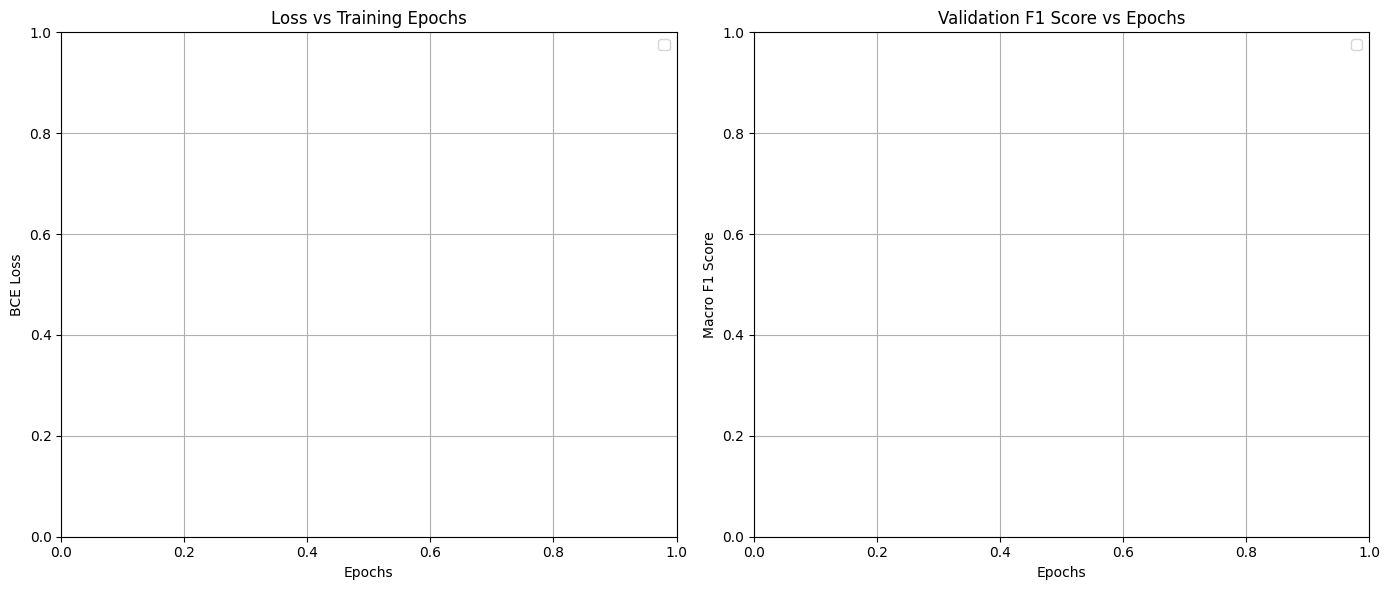


--- OPTUNA INTERACTIVE VISUALIZATIONS ---
Note: You can hover and interact with these plots!


In [ ]:
import matplotlib.pyplot as plt
import optuna

# 1. Plot the Learning Curves (Baseline DistilBERT vs Final Optimized Model)
try:
    plt.figure(figsize=(14, 6))

    # Plot 1: Train Loss Comparison
    plt.subplot(1, 2, 1)
    if 'baseline_history' in locals():
        plt.plot(baseline_history['train_loss'], label='Baseline Train Loss', linestyle='dotted', color='lightblue', marker='s')
    if 'final_history' in locals():
        plt.plot(history['train_loss'], label='Optimized Train Loss', marker='o', color='blue')
        plt.plot(history['val_loss'], label='Optimized Val Loss', marker='o', color='red')

    plt.title('Loss vs Training Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('BCE Loss')
    plt.legend()
    plt.grid(True)

    # Plot 2: Macro F1 Score Over Time
    plt.subplot(1, 2, 2)
    if 'baseline_history' in locals():
        plt.plot(baseline_history['val_macro_f1'], label='Baseline Validation F1', color='lightgreen', marker='s', linestyle='dotted')
    if 'final_history' in locals():
        plt.plot(history['val_macro_f1'], label='Optimized Validation F1', color='green', marker='o', linestyle='dashed')

    plt.title('Validation F1 Score vs Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Macro F1 Score')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

except Exception as e:
    print("[!] Could not plot final learning curves.", e)

# 2. Plot Optuna Hyperparameter Importance & History (Interactive)
try:
    # Pull the memory state directly from the local SQLite database!
    viz_study = optuna.load_study(study_name="transformer_tuning", storage="sqlite:///optuna_study.db")

    print("\n--- OPTUNA INTERACTIVE VISUALIZATIONS ---")
    print("Note: You can hover and interact with these plots!")

    # Plot 1: Show the progression of trials
    fig1 = optuna.visualization.plot_optimization_history(viz_study)
    fig1.show(renderer='colab')

    # Plot 2: Show a mathematical breakdown of which hyperparameter impacted the accuracy the most
    fig2 = optuna.visualization.plot_param_importances(viz_study)
    fig2.show(renderer='colab')

except Exception as e:
    print("[!] Could not plot Optuna visualizations. Have you completed at least 1 trial in the Optuna cell?", e)
